## Mutation Data Preprocessing and Quality Control

This notebook prepares and validates the raw mutation data for downstream machine learning analysis.

### Inputs
- `gene_presence_data_gnomad_1_0.csv`: raw mutation data for patients from the oligometastatic cohort
- `primpluri_gene_new_220925.csv`: raw mutation data for patients from the polymetastatic cohort

### Output
- `20260505-mcpp-breast-mutation-all-metastatic-data-preprocessing-qc-final.csv`: final combined and quality-controlled mutation feature table containing:
  - `sample_id`
  - `mutation_source`
  - binary mutation features for all retained genes

### Objective
The objective is to build a clean mutation feature table that can be used for downstream machine learning models predicting oligometastatic vs polymetastatic status.

### Main steps
1. Load the two raw mutation datasets.
2. Standardize the sample identifier column.
3. Remove non-feature columns irrelevant to the current prediction task.
4. Combine both datasets into a single mutation matrix.
5. Perform quality control checks on the combined dataset.
6. Remove non-informative and very rare mutation features.
7. Save an intermediate filtered mutation dataset for external redundancy analysis.
8. Load the Phi/Fisher pairwise association results generated externally using `scripts/OligoPolyThesis/mutation_phi_fisher_analysis.py`.
9. Remove highly redundant mutation features.
10. Save the final quality-controlled mutation dataset.

In [1]:
# Display precision only; analytical values and saved artifacts stay unchanged.
from pathlib import Path as _DisplayPath
import sys as _display_sys
_display_root = _DisplayPath.cwd()
while not (_display_root / "scripts").is_dir() and _display_root != _display_root.parent:
    _display_root = _display_root.parent
if str(_display_root) not in _display_sys.path:
    _display_sys.path.insert(0, str(_display_root))
from scripts.OligoPolyThesis.utils_ml_oligopoly import thesis_display, thesis_print

import os
import sys
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

# ── Project root setup ───────────────────────────────────────────────────
ROOT = Path.cwd()
while not (ROOT / "scripts").exists() and ROOT != ROOT.parent:
    ROOT = ROOT.parent

if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

from scripts.OligoPolyThesis.utils_ml_oligopoly import annotate_genes_with_symbols, annotate_gene_pairs_with_symbols, plot_grouped_histogram, resolve_gene_ids_via_primary_sources
from scripts.OligoPolyThesis.utils_ml_oligopoly import plot_frequency, adjust_p_values


# ── Data paths ───────────────────────────────────────────────────────────
path_directory = Path("/mnt/data3/MCPP-Breast/Mutation-Data/")

file_oligo = path_directory / "gene_presence_data_gnomad_1_0.csv"
file_poly = path_directory / "primpluri_gene_new_220925.csv"

mut_oligo = pd.read_csv(file_oligo)
mut_poly = pd.read_csv(file_poly)

thesis_print("Oligo mutation data shape:", mut_oligo.shape)
thesis_print("Poly mutation data shape:", mut_poly.shape)

Oligo mutation data shape: ('44', '10386')
Poly mutation data shape: ('68', '13691')


### Standardize the Sample Identifier Column ###

In both files, the first column (`Unnamed: 0`) corresponds to the sample identifier.

We rename it to `sample_id` to make the structure explicit and consistent across datasets.

In [2]:
mut_oligo = mut_oligo.rename(columns={'Unnamed: 0': 'sample_id'})
mut_poly = mut_poly.rename(columns={'Unnamed: 0': 'sample_id'})

thesis_print("Oligo columns after renaming:")
thesis_print(mut_oligo.columns.tolist()[:10])

thesis_print("\nPoly columns after renaming:")
thesis_print(mut_poly.columns.tolist()[:10])

Oligo columns after renaming:
['sample_id', 'Progress', '100129098', '100141515', '10018', '10045', '100507055', '100507588', '100528030', '10077']

Poly columns after renaming:
['sample_id', '10004', '100101467', '100129098', '100129528', '100141515', '10018', '1002', '10045', '100506564']


### Remove Non-Feature Columns ###

The oligo mutation file contains an additional column called `Progress`, which was used in a previous project with a different target.

Since the current objective is to predict whether patients will be oligometastatic or plurimetastatic, this column is not relevant to the present task and is removed from the mutation feature table.

In [3]:
if 'Progress' in mut_oligo.columns:
    mut_oligo = mut_oligo.drop(columns=['Progress'])
    thesis_print("'Progress' column removed from oligo mutation data.")
else:
    thesis_print("No 'Progress' column found in oligo mutation data.")

'Progress' column removed from oligo mutation data.


### Add Source Cohort Information

A source column records the oligometastatic or polymetastatic dataset for each sample, allowing later quality-control checks.

In [4]:
mut_oligo = mut_oligo.copy().assign(mutation_source="oligo")
mut_poly = mut_poly.copy().assign(mutation_source="poly")

### Compare Mutation Feature Columns Across Datasets ###

Because the oligo and poly mutation files were generated separately, they may not contain exactly the same mutation feature columns.

We compare the mutation columns in both files before combining them.

In [5]:
oligo_cols = set(mut_oligo.columns) - {'sample_id', 'mutation_source'}
poly_cols = set(mut_poly.columns) - {'sample_id', 'mutation_source'}

common_genes = oligo_cols & poly_cols
only_oligo = oligo_cols - poly_cols
only_poly = poly_cols - oligo_cols

thesis_print("Number of common mutation columns:", len(common_genes))
thesis_print("Number of mutation columns only in oligo:", len(only_oligo))
thesis_print("Number of mutation columns only in poly:", len(only_poly))

Number of common mutation columns: 8604
Number of mutation columns only in oligo: 1780
Number of mutation columns only in poly: 5086


### Combine Oligo and Poly Mutation Data ###

We concatenate both mutation datasets into a single mutation table.

Since the two files do not necessarily contain exactly the same mutation columns, pandas aligns them automatically. Missing mutation entries introduced by this alignment will be handled in the next step.

In [6]:
mutation_combined = pd.concat([mut_oligo, mut_poly], ignore_index=True, sort=False)

thesis_print("Combined mutation data shape:", mutation_combined.shape)

Combined mutation data shape: ('112', '15472')


### Fill Missing Mutation Entries After Combination ###

After concatenation, mutation columns that were exclusive to one source cohort appear as missing values (`NaN`) in the other cohort.

Because the matrix represents mutation presence/absence, these missing values are replaced with `0`.

In [7]:
metadata_cols = ['sample_id', 'mutation_source']
mutation_cols = [col for col in mutation_combined.columns if col not in metadata_cols]

mutation_combined[mutation_cols] = mutation_combined[mutation_cols].fillna(0).astype(int)

thesis_print("Total number of missing values after filling:", mutation_combined.isna().sum().sum())
thesis_print("Combined mutation data shape after filling:", mutation_combined.shape)

Total number of missing values after filling: 0
Combined mutation data shape after filling: ('112', '15472')


### Harmonise Gene Identifiers via Gene Symbol

Some mutation feature columns use different ID systems (Ensembl vs. bare Entrez Gene IDs) for what may be the same underlying gene. Before any QC or redundancy analysis, we resolve every column to its gene symbol using the existing `annotate_genes_with_symbols` function. Columns that resolve to the same symbol represent the same gene, whichever ID system was originally used, so they are merged.

In [8]:
gene_id_lookup_df = pd.DataFrame({"gene": mutation_cols})

gene_id_lookup_df = annotate_genes_with_symbols(
    gene_id_lookup_df,
    gene_col="gene",
    species="human",
    verbose=True,
    fill_unmapped=False,
)

n_mapped = gene_id_lookup_df["gene_symbol"].notna().sum()
thesis_print(f"Resolved {n_mapped} of {len(gene_id_lookup_df)} columns to a gene symbol.")

symbol_groups = (
    gene_id_lookup_df
    .dropna(subset=["gene_symbol"])
    .groupby("gene_symbol")["gene"]
    .apply(list)
)

duplicate_symbol_groups = symbol_groups[symbol_groups.apply(len) > 1]

thesis_print(f"\nFound {len(duplicate_symbol_groups)} gene symbols represented by more than one column:")
for symbol, cols in duplicate_symbol_groups.items():
    thesis_print(f"  {symbol}: {cols}")

for symbol, cols in duplicate_symbol_groups.items():
    # Prefer keeping an Ensembl-style column name if one exists in the group
    ensembl_cols = [c for c in cols if str(c).startswith("ENSG")]
    keep_col = ensembl_cols[0] if ensembl_cols else cols[0]
    drop_cols = [c for c in cols if c != keep_col]

    merged = mutation_combined[cols].max(axis=1)  # logical OR for binary indicators
    mutation_combined[keep_col] = merged
    mutation_combined = mutation_combined.drop(columns=drop_cols)

# Refresh mutation_cols to reflect the harmonised column set
mutation_cols = [col for col in mutation_combined.columns if col not in metadata_cols]

thesis_print("\nMutation matrix shape after harmonisation:", mutation_combined[mutation_cols].shape)

['124904106', '124904176', '128966744', 'ENSG00000203546', 'ENSG00000273748', 'ENSG00000273957', 'ENSG00000278082', 'ENSG00000283465', 'ENSG00000284912', 'ENSG00000285130', 'ENSG00000288438', 'ENSG00000289747', 'ENSG00000291313', 'ENSG00000293562', 'ENSG00000293565', 'ENSG00000293570', 'ENSG00000300293', 'ENSG00000300510', 'ENSG00000310562']
Resolved 15451 of 15470 columns to a gene symbol.

Found 970 gene symbols represented by more than one column:
  ABCC10: ['ENSG00000124574', '89845']
  ABCC11: ['85320', 'ENSG00000121270']
  ABCC5: ['ENSG00000114770', '10057']
  ABCC6: ['ENSG00000091262', 'ENSG00000275331']
  ABCD1: ['215', 'ENSG00000101986']
  ABCD4: ['5826', 'ENSG00000119688']
  ABCG5: ['ENSG00000138075', '64240']
  ABHD11: ['ENSG00000106077', '83451']
  ABHD12: ['ENSG00000100997', '26090']
  ABLIM3: ['ENSG00000173210', '22885']
  ACACB: ['ENSG00000076555', '32']
  ACAD8: ['ENSG00000151498', '27034']
  ACAN: ['ENSG00000157766', '176']
  ACE: ['1636', 'ENSG00000159640']
  ACSM2A: 

### Verify No Further Duplicate Gene Symbols Remain

Repeating symbol resolution on the harmonised columns checks that each gene symbol is represented only once.

In [9]:
verification_lookup_df = pd.DataFrame({"gene": mutation_cols})

verification_lookup_df = annotate_genes_with_symbols(
    verification_lookup_df,
    gene_col="gene",
    species="human",
    verbose=True,
    fill_unmapped=False,
)

verification_symbol_groups = (
    verification_lookup_df
    .dropna(subset=["gene_symbol"])
    .groupby("gene_symbol")["gene"]
    .apply(list)
)

remaining_duplicate_groups = verification_symbol_groups[verification_symbol_groups.apply(len) > 1]

thesis_print(f"Remaining gene symbols represented by more than one column: {len(remaining_duplicate_groups)}")

if len(remaining_duplicate_groups) > 0:
    thesis_print("\nThese should be investigated before proceeding:")
    for symbol, cols in remaining_duplicate_groups.items():
        thesis_print(f"  {symbol}: {cols}")
else:
    thesis_print("Harmonisation is complete — no gene symbol is split across multiple columns.")

['124904106', '124904176', '128966744', 'ENSG00000203546', 'ENSG00000273748', 'ENSG00000273957', 'ENSG00000278082', 'ENSG00000283465', 'ENSG00000284912', 'ENSG00000285130', 'ENSG00000288438', 'ENSG00000289747', 'ENSG00000291313', 'ENSG00000293562', 'ENSG00000293565', 'ENSG00000293570', 'ENSG00000300293', 'ENSG00000300510', 'ENSG00000310562']
Remaining gene symbols represented by more than one column: 0
Harmonisation is complete — no gene symbol is split across multiple columns.


### Second-Pass Lookup for Unmapped Gene IDs

The 18 columns that mygene.info could not resolve to a symbol are checked again directly against the Ensembl REST API (for ENSG-format IDs) and the NCBI E-utils API (for bare numeric Entrez-style IDs), since these primary sources are sometimes more up to date than mygene's indexed database.

In [10]:
unmapped_ids = verification_lookup_df[
    verification_lookup_df["gene_symbol"].isna()
]["gene"].tolist()

thesis_print(f"Attempting second-pass lookup for {len(unmapped_ids)} unmapped IDs.")

second_pass_df = resolve_gene_ids_via_primary_sources(unmapped_ids)
thesis_display(second_pass_df)

n_recovered = second_pass_df["gene_symbol"].notna().sum()
thesis_print(f"\nRecovered symbols for {n_recovered} of {len(unmapped_ids)} previously unmapped IDs.")

Attempting second-pass lookup for 19 unmapped IDs.


,gene,gene_symbol,status
0,124904106,LOC124904106,found
1,124904176,LOC124904176,found
2,128966744,LOC128966744,found
3,ENSG00000273748,None,found_no_symbol
4,ENSG00000289747,None,found_no_symbol
5,ENSG00000291313,None,found_no_symbol
6,ENSG00000293565,None,found_no_symbol
7,ENSG00000293570,None,found_no_symbol
8,ENSG00000203546,None,found_no_symbol
9,ENSG00000273957,None,found_no_symbol



Recovered symbols for 3 of 19 previously unmapped IDs.


### Retry Failed Lookups

16 of the 18 previously unmapped IDs failed with server errors (HTTP 500) or connection errors during the first lookup attempt, rather than returning a confirmed "not found". They are retried here with longer delays and retry logic before drawing any conclusion.

In [11]:
failed_ids = second_pass_df[
    second_pass_df["gene_symbol"].isna() &
    (second_pass_df["status"] != "withdrawn_or_not_found")
]["gene"].tolist()

thesis_print(f"Retrying {len(failed_ids)} IDs that failed due to technical errors.")

retry_df = resolve_gene_ids_via_primary_sources(
    failed_ids, max_retries=2, base_wait_seconds=2.0, request_delay_seconds=1.0
)
thesis_display(retry_df)

n_recovered_retry = retry_df["gene_symbol"].notna().sum()
thesis_print(f"\nRecovered symbols for {n_recovered_retry} of {len(failed_ids)} previously failed IDs.")

Retrying 16 IDs that failed due to technical errors.


,gene,gene_symbol,status
0,ENSG00000273748,None,found_no_symbol
1,ENSG00000289747,None,found_no_symbol
2,ENSG00000291313,None,found_no_symbol
3,ENSG00000293565,None,found_no_symbol
4,ENSG00000293570,None,found_no_symbol
5,ENSG00000203546,None,found_no_symbol
6,ENSG00000273957,None,found_no_symbol
7,ENSG00000278082,None,found_no_symbol
8,ENSG00000283465,None,found_no_symbol
9,ENSG00000284912,None,found_no_symbol



Recovered symbols for 0 of 16 previously failed IDs.


### Final Retry for Persistently Failing IDs

3 of the 16 IDs still returned server errors (HTTP 500) after the first retry. They are given one more attempt, with longer waits and more retries per ID. IDs that still fail are treated as unresolved because of a persistent Ensembl API issue, not because of a property of the genes themselves.

In [12]:
still_failed_ids = retry_df[retry_df["status"] == "http_error_500"]["gene"].tolist()

thesis_print(f"Final retry for {len(still_failed_ids)} persistently failing IDs: {still_failed_ids}")

final_df = resolve_gene_ids_via_primary_sources(
    still_failed_ids, max_retries=4, base_wait_seconds=5.0, request_delay_seconds=2.0
)
thesis_display(final_df)

n_recovered_final = final_df["gene_symbol"].notna().sum()
thesis_print(f"\nRecovered symbols for {n_recovered_final} of {len(still_failed_ids)} persistently failing IDs.")

Final retry for 0 persistently failing IDs: []


,gene,gene_symbol,status



Recovered symbols for 0 of 0 persistently failing IDs.


## Mutation Data Quality Control ##

Quality control is performed on the combined mutation dataset to verify that it is structurally valid, binary, non-redundant, and suitable for downstream analysis.

The main checks include:
1. sample-level quality control;
2. binary validation of mutation features;
3. identification of non-informative mutation columns;
4. sparsity assessment;
5. mutation burden inspection.

### Sample-Level Quality Control ###

We verify:
- whether `sample_id` is present for all rows;
- whether sample identifiers are unique;
- how many samples come from each source cohort.

In [13]:
thesis_print("Missing sample_id values:", mutation_combined['sample_id'].isna().sum())
thesis_print("Duplicated sample_id values:", mutation_combined['sample_id'].duplicated().sum())

thesis_print("\nSamples by mutation source:")
thesis_print(mutation_combined['mutation_source'].value_counts(dropna=False))

Missing sample_id values: 0
Duplicated sample_id values: 0

Samples by mutation source:
                count
mutation_source      
poly               68
oligo              44


### Check Whether Mutation Features Are Binary ###

Mutation feature columns should contain only `0` or `1`.

We verify whether any mutation column contains unexpected values.

In [14]:
non_binary_cols = []

for col in mutation_cols:
    unique_vals = set(mutation_combined[col].dropna().unique())
    if not unique_vals.issubset({0, 1}):
        non_binary_cols.append((col, sorted(unique_vals)))

thesis_print("Number of non-binary mutation columns:", len(non_binary_cols))

if non_binary_cols:
    thesis_print("\nExamples of non-binary columns:")
    for col, vals in non_binary_cols[:20]:
        thesis_print(f"{col}: {vals}")
else:
    thesis_print("All mutation feature columns are binary.")

Number of non-binary mutation columns: 0
All mutation feature columns are binary.


### Identify Non-Informative Mutation Features ###

We identify mutation columns that are:
- always `0` across all samples;
- always `1` across all samples.

Such columns do not provide useful information for modelling and are removed.

In [15]:
all_zero_cols = [col for col in mutation_cols if mutation_combined[col].sum() == 0]
all_one_cols = [col for col in mutation_cols if mutation_combined[col].sum() == len(mutation_combined)]

thesis_print("Number of all-zero mutation columns:", len(all_zero_cols))
thesis_print("Number of all-one mutation columns:", len(all_one_cols))

thesis_print("\nExamples of all-zero columns:")
thesis_print(all_zero_cols[:20])

thesis_print("\nExamples of all-one columns:")
thesis_print(all_one_cols[:20])

cols_to_remove_noninformative = sorted(set(all_zero_cols + all_one_cols))
mutation_qc = mutation_combined.drop(columns=cols_to_remove_noninformative)

thesis_print("\nShape before removing non-informative columns:", mutation_combined.shape)
thesis_print("Shape after removing non-informative columns:", mutation_qc.shape)

Number of all-zero mutation columns: 0
Number of all-one mutation columns: 0

Examples of all-zero columns:
[]

Examples of all-one columns:
[]

Shape before removing non-informative columns: ('112', '14495')
Shape after removing non-informative columns: ('112', '14495')


### Check for Duplicated Mutation Feature Names ###

We verify whether any mutation feature names are duplicated in the combined dataset.

In [16]:
duplicated_col_names = mutation_combined.columns[mutation_combined.columns.duplicated()].tolist()

thesis_print("Number of duplicated column names:", len(duplicated_col_names))
thesis_print("Duplicated column names:")
thesis_print(duplicated_col_names[:20])

Number of duplicated column names: 0
Duplicated column names:
[]


### Assess Dataset Sparsity ###

Mutation matrices are usually sparse. We compute the proportion of zero values across all mutation feature columns.

In [17]:
mutation_matrix = mutation_combined[mutation_cols]

total_entries = mutation_matrix.shape[0] * mutation_matrix.shape[1]
num_zeros = (mutation_matrix == 0).sum().sum()
num_ones = (mutation_matrix == 1).sum().sum()

sparsity = num_zeros / total_entries

thesis_print("Total mutation matrix entries:", total_entries)
thesis_print("Number of zeros:", num_zeros)
thesis_print("Number of ones:", num_ones)
thesis_print(f"Sparsity (proportion of zeros): {sparsity:.3f}")

Total mutation matrix entries: 1623216
Number of zeros: 1552444
Number of ones: 70772
Sparsity (proportion of zeros): 0.956


### Mutation Burden per Sample ###

We calculate the number of mutated genes per sample and inspect its distribution overall and by source cohort.

In [18]:
mutation_combined = mutation_combined.copy().assign(
    n_mutated_genes=mutation_combined[mutation_cols].sum(axis=1)
)

thesis_print("Summary of mutated genes per sample:")
thesis_display(mutation_combined["n_mutated_genes"].describe())

thesis_print("\nMutation burden by source cohort:")
thesis_display(mutation_combined.groupby("mutation_source")["n_mutated_genes"].describe())

Summary of mutated genes per sample:


,n_mutated_genes
count,112
mean,631.893
std,542.716
min,167
25%,316
50%,386.500
75%,460.500
max,2026



Mutation burden by source cohort:


,count,mean,std,min,25%,50%,75%,max
mutation_source,,,,,,,,
oligo,44,489.886,346.148,237.000,354.750,401.000,423.250,1926.000
poly,68,723.779,623.906,167.000,291.000,373.500,1340.000,2026.000


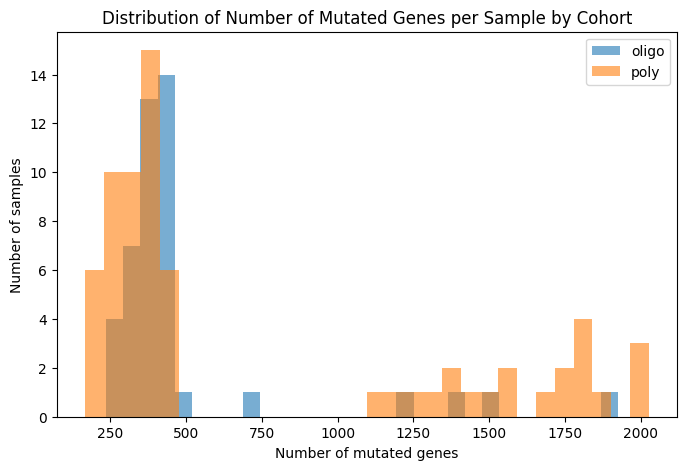

In [19]:
plot_grouped_histogram(
    df=mutation_combined,
    value_col="n_mutated_genes",
    group_col="mutation_source",
    groups=["oligo", "poly"],
    bins=30,
    alpha=0.6,
    title="Distribution of Number of Mutated Genes per Sample by Cohort",
    xlabel="Number of mutated genes",
    ylabel="Number of samples"
)

### Gene Mutation Frequency

We compute how many samples have each mutation feature equal to `1`.

This helps identify extremely rare or highly prevalent mutation features before applying the rare-feature filtering step.

In [20]:
gene_mutation_counts = mutation_combined[mutation_cols].sum(axis=0).sort_values(ascending=False)

thesis_display(gene_mutation_counts.head(20))
thesis_display(gene_mutation_counts.tail(20))

,0
ENSG00000155657,75
ENSG00000215455,56
ENSG00000185567,49
ENSG00000154358,48
ENSG00000127603,44
ENSG00000158486,42
ENSG00000188738,42
ENSG00000178209,41
ENSG00000142449,41
ENSG00000185842,40


,0
ENSG00000292253,1
ENSG00000292308,1
ENSG00000292388,1
ENSG00000122121,1
ENSG00000281994,1
ENSG00000282757,1
ENSG00000283139,1
ENSG00000283227,1
ENSG00000283268,1
ENSG00000288649,1


### Visualise Most Frequently Mutated Genes

The table above shows the top and bottom genes by mutation frequency. The plot below visualises the top 30 most frequently mutated genes across the combined cohort.


--- Plotting: Top 30 Most Frequently Mutated Genes ---


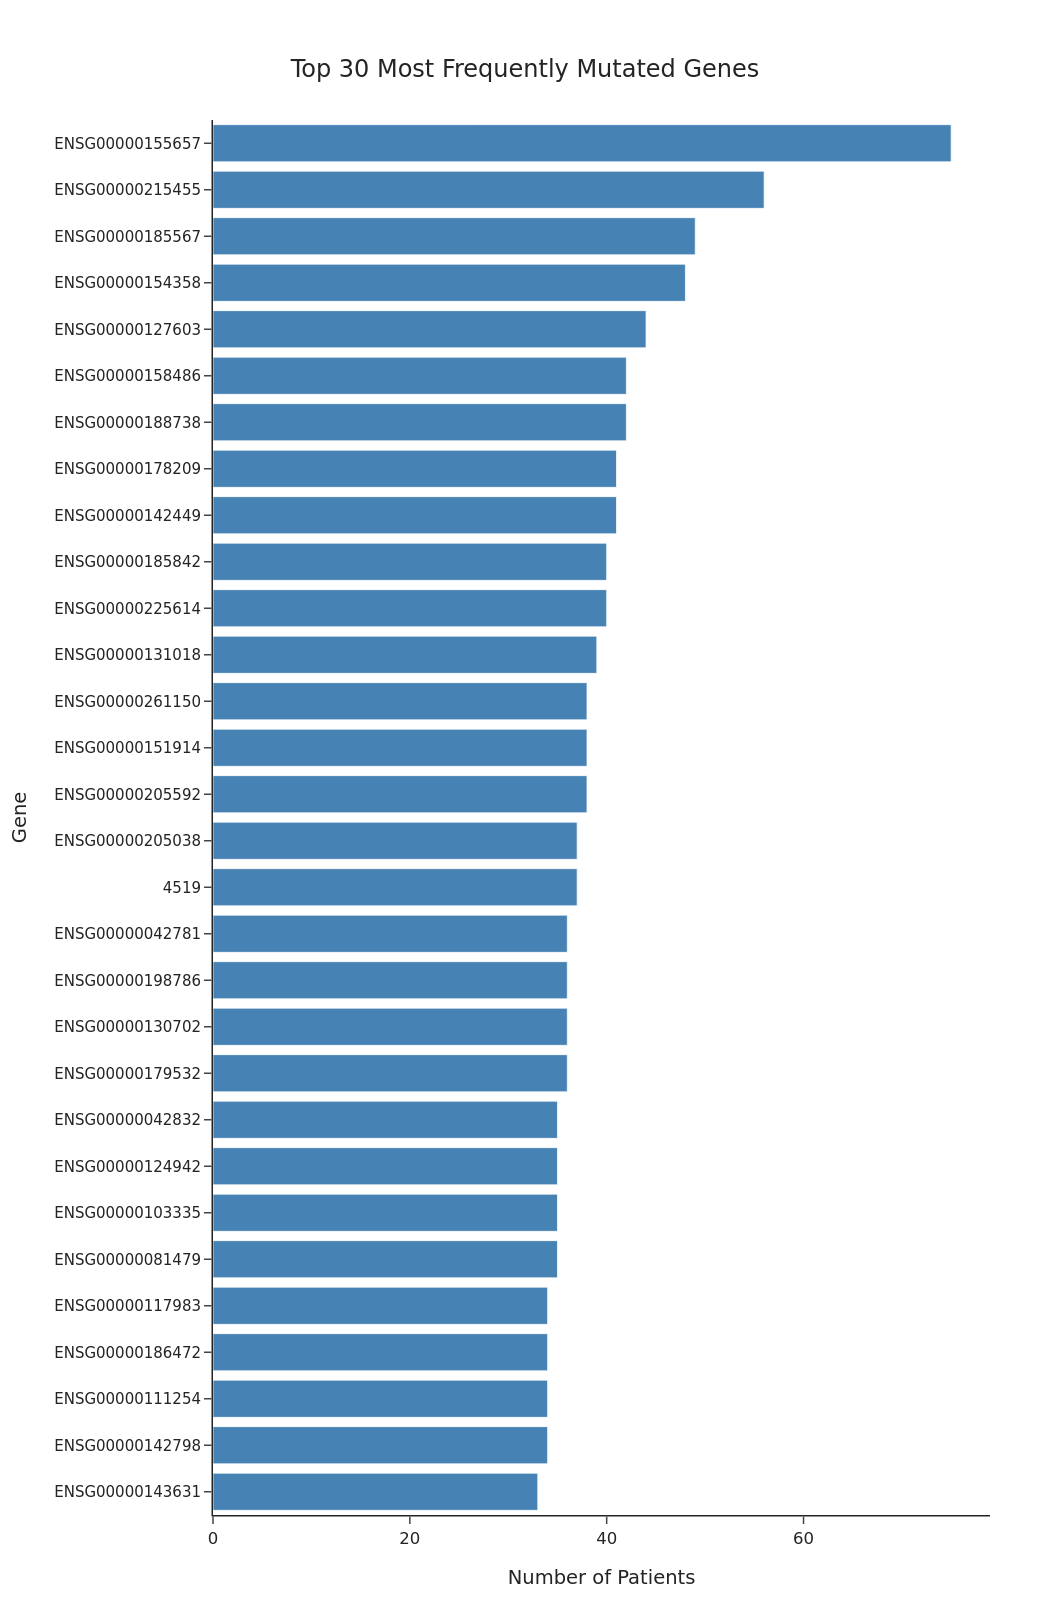

In [21]:
plot_frequency(
    non_zero_coef_counts=gene_mutation_counts.head(30).to_dict(),
    title="Top 30 Most Frequently Mutated Genes",
    x_axis_title="Number of Patients",
    y_axis_title="Gene",
    bar_color="steelblue",
    interactive=False
)

### Remove Very Rare Mutation Features

As an initial filtering step, mutation features present in fewer than **5% of patients** are removed.

This percentage-based threshold scales with cohort size and helps:
- reduce noise from extremely rare mutation events;
- improve computational feasibility for downstream redundancy analysis;
- avoid unstable associations driven by features observed in only a very small number of patients.

In this cohort, the 5% threshold corresponds to retaining only mutation features present in at least the minimum number of patients defined below.

In [22]:
rare_threshold_pct = 0.05  # 5%
min_patients = int(np.ceil(rare_threshold_pct * mutation_qc.shape[0]))

thesis_print(f"Total number of patients: {mutation_qc.shape[0]}")
thesis_print(f"Rare feature threshold: {rare_threshold_pct*100:.1f}%")
thesis_print(f"Minimum number of patients required to keep a feature: {min_patients}")

rare_cols = gene_mutation_counts[gene_mutation_counts < min_patients].index.tolist()

thesis_print(f"\nNumber of mutation features present in fewer than {min_patients} patients:", len(rare_cols))
thesis_print("Examples:")
thesis_print(rare_cols[:30])

mutation_qc_filtered = mutation_qc.drop(columns=rare_cols)

thesis_print("\nShape before removing very rare columns:", mutation_qc.shape)
thesis_print("Shape after removing very rare columns:", mutation_qc_filtered.shape)

# Columns that will enter the redundancy analysis
mutation_cols_for_assoc = [
    col for col in mutation_qc_filtered.columns
    if col not in ['sample_id', 'mutation_source', 'n_mutated_genes']
]

n_pairs = len(mutation_cols_for_assoc) * (len(mutation_cols_for_assoc) - 1) // 2

thesis_print("\nNumber of mutation columns entering redundancy analysis:", len(mutation_cols_for_assoc))
thesis_print("Number of pairs to analyse:", n_pairs)

Total number of patients: 112
Rare feature threshold: 5.0%
Minimum number of patients required to keep a feature: 6

Number of mutation features present in fewer than 6 patients: 9937
Examples:
['ENSG00000198205', 'ENSG00000292304', 'ENSG00000143006', '112268241', '102723996', 'ENSG00000291738', 'ENSG00000143079', 'ENSG00000141946', 'ENSG00000143196', 'ENSG00000143217', 'ENSG00000143228', 'ENSG00000120915', 'ENSG00000143061', 'ENSG00000123594', 'ENSG00000310560', 'ENSG00000198336', 'ENSG00000090612', 'ENSG00000090674', 'ENSG00000198390', 'ENSG00000198265', 'ENSG00000141560', 'ENSG00000141569', 'ENSG00000143850', 'ENSG00000143727', 'ENSG00000143751', 'ENSG00000143799', 'ENSG00000143842', 'ENSG00000011638', 'ENSG00000121988', 'ENSG00000172345']

Shape before removing very rare columns: ('112', '14495')
Shape after removing very rare columns: ('112', '4558')

Number of mutation columns entering redundancy analysis: 4556
Number of pairs to analyse: 10376290


### Visualise the Rare-Feature Threshold

The histogram below shows the distribution of mutation frequency across all genes, with the 5% threshold marked.

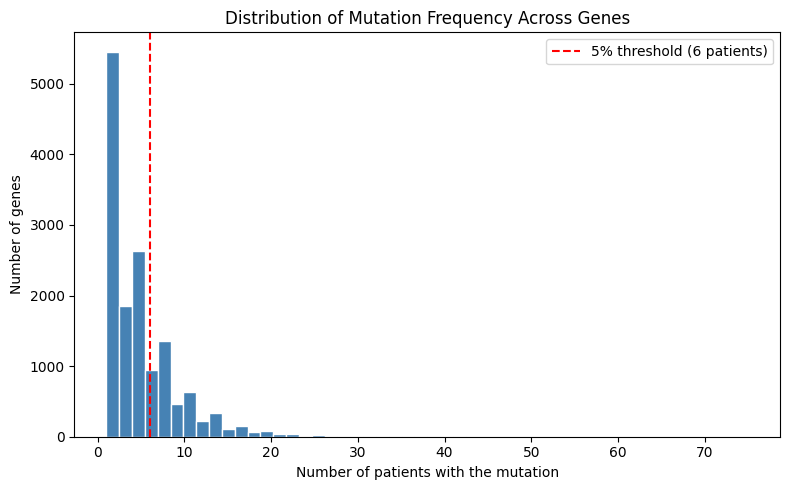

In [23]:
plt.figure(figsize=(8, 5))
plt.hist(gene_mutation_counts.values, bins=50, color="steelblue", edgecolor="white")
plt.axvline(min_patients, color="red", linestyle="--", label=f"5% threshold ({min_patients} patients)")
plt.xlabel("Number of patients with the mutation")
plt.ylabel("Number of genes")
plt.title("Distribution of Mutation Frequency Across Genes")
plt.legend()
plt.tight_layout()
plt.show()

### Inspect Intermediate QC-Filtered Mutation Dataset ###

We inspect the first rows of the mutation dataset after removing non-informative and very rare mutation features.

In [24]:
thesis_display(mutation_qc_filtered.head())

,sample_id,100129098,100861540,101929937,124900214,124900418,124901030,124901178,124901227,124901643,...,ENSG00000270231,ENSG00000272602,ENSG00000273899,ENSG00000274587,ENSG00000277281,ENSG00000277494,ENSG00000277585,ENSG00000283297,ENSG00000283473,ENSG00000300510
0,101B,0,1,0,0,0,0,0,0,1,...,0,0,0,0,0,0,0,0,0,0
1,108B,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
2,10B,1,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
3,110B,1,0,0,0,0,0,1,0,1,...,0,0,0,0,0,0,0,0,0,0
4,115B,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0


## Redundancy Analysis for Binary Mutation Features

To assess redundancy between binary mutation variables, we evaluate pairwise associations using:

- **Phi coefficient**, to quantify the strength of association between two binary variables;
- **Fisher's exact test**, to assess whether the observed association is statistically significant.

The pairwise Phi/Fisher computation is computationally expensive, so it is performed externally using the script `scripts/OligoPolyThesis/mutation_phi_fisher_analysis.py`.

### Interpretation
- **High Phi (`|phi| > 0.85`) + low p-value (`p < 0.05`)**: strong and statistically significant association, suggesting possible redundancy.
- **Low Phi + high p-value**: variables are likely independent; both can be kept.
- **High Phi + high p-value**: possible instability due to low frequencies; feature frequencies and biological context should be inspected before deciding.

### Save Filtered Mutation Dataset for External Redundancy Analysis

The mutation dataset after structural QC and rare-feature filtering is saved as an intermediate file.

This file is used as input for the external script `scripts/OligoPolyThesis/mutation_phi_fisher_analysis.py`, which computes pairwise Phi coefficients and Fisher exact test p-values between mutation features.

In [25]:
# Save the filtered mutation dataset for the external Phi/Fisher analysis

mutation_qc_filtered.to_csv(
    "/mnt/data3/MCPP-Breast/Mutation-Data/mutation_qc_filtered.csv",
    index=False
)

### Load Pairwise Phi/Fisher Results Generated Externally

After saving the filtered mutation dataset, the pairwise Phi/Fisher redundancy analysis is run externally on the server using `scripts/OligoPolyThesis/mutation_phi_fisher_analysis.py`.

The script processes feature pairs in chunks for computational efficiency, automatically merges the chunk outputs into a single combined results file, and removes the intermediate chunk files.

Here, we load the final combined Phi/Fisher results back into the notebook for redundancy filtering.

In [26]:
path_directory = "/mnt/data3/MCPP-Breast/Mutation-Data"

combined_phi_fisher_path = os.path.join(
    path_directory,
    "20260813-mutation_phi_fisher_results_combined.csv"
)

phi_fisher_df = pd.read_csv(combined_phi_fisher_path)

thesis_print("Loaded combined Phi/Fisher results from:")
thesis_print(combined_phi_fisher_path)

thesis_print("\nCombined dataframe shape:", phi_fisher_df.shape)
thesis_display(phi_fisher_df.head())

Loaded combined Phi/Fisher results from:
/mnt/data3/MCPP-Breast/Mutation-Data/20260813-mutation_phi_fisher_results_combined.csv

Combined dataframe shape: ('28824', '10')


,Feature1,Feature2,Phi,P_value,n11,n10,n01,n00,freq_feature1,freq_feature2
0,100129098,ENSG00000066084,0.501,0.00036,4,3,4,101,7,8
1,100861540,ENSG00000002587,0.550,0.000159,4,2,4,102,6,8
2,100861540,ENSG00000007341,0.513,0.000282,4,2,5,101,6,9
3,100861540,ENSG00000081087,0.559,3.35e-05,5,1,7,99,6,12
4,100861540,ENSG00000091136,0.659,5.46e-06,5,1,4,102,6,9


### Inspect Strongest Binary Associations

We sort all retained mutation-feature pairs by the absolute Phi coefficient to inspect the strongest binary associations.

These pairs may represent redundant mutation features, co-occurrence patterns, or biologically related signals. The strongest associations should be interpreted together with Fisher's exact test results and, when relevant, biological or cancer-related literature.

In [27]:
phi_fisher_df['abs_phi'] = phi_fisher_df['Phi'].abs()
phi_fisher_sorted = phi_fisher_df.sort_values(by='abs_phi', ascending=False)

thesis_display(phi_fisher_sorted.head(20))

,Feature1,Feature2,Phi,P_value,n11,n10,n01,n00,freq_feature1,freq_feature2,abs_phi
9357,ENSG00000114316,ENSG00000188315,0.938,1.89e-11,8,1,0,103,9,8,0.938
17197,ENSG00000145975,ENSG00000184313,0.874,2.63e-13,12,2,1,97,14,13,0.874
15471,ENSG00000138160,ENSG00000177300,0.858,1.17e-08,6,0,2,104,6,8,0.858
11502,ENSG00000123095,ENSG00000175766,0.858,1.17e-08,6,2,0,104,8,6,0.858
26208,ENSG00000197506,ENSG00000198610,0.848,2.03e-08,6,1,1,104,7,7,0.848
15433,ENSG00000138109,ENSG00000162910,0.824,2.66e-07,5,1,1,105,6,6,0.824
27409,ENSG00000007306,ENSG00000101438,0.824,2.66e-07,5,1,1,105,6,6,0.824
27591,ENSG00000084234,ENSG00000152465,0.824,2.66e-07,5,1,1,105,6,6,0.824
15083,ENSG00000136839,ENSG00000147140,0.824,2.66e-07,5,1,1,105,6,6,0.824
28394,ENSG00000147905,ENSG00000175766,0.824,2.66e-07,5,1,1,105,6,6,0.824


### Visualise Strongest Feature-Pair Associations

The bar chart below shows the 20 mutation feature pairs with the strongest association (by |Phi|), colored by statistical significance after FDR correction (green = significant at adjusted p < 0.05, red = not significant after correction).

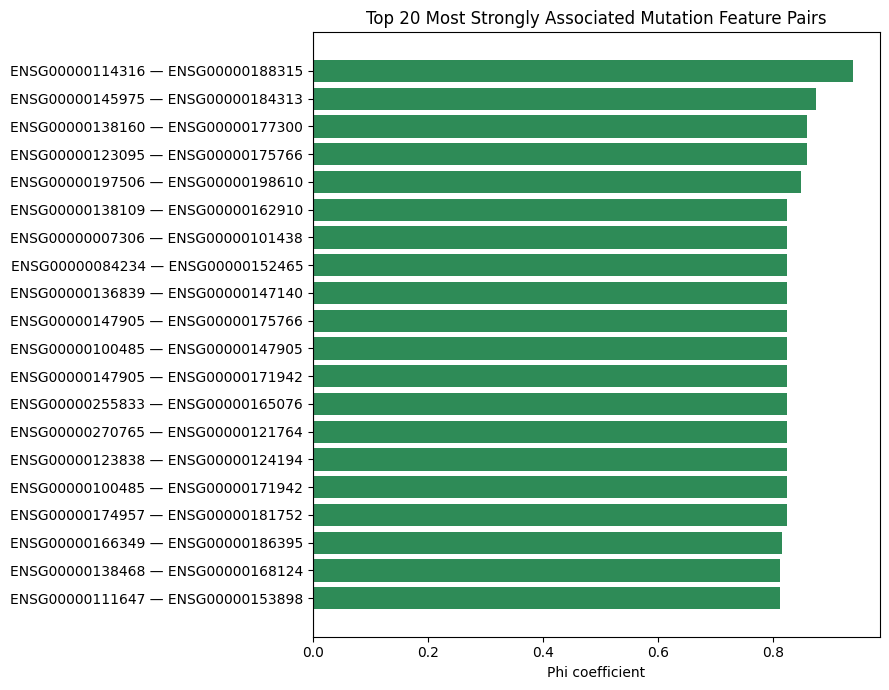

In [28]:
phi_fisher_df = adjust_p_values(
    phi_fisher_df,
    method="fdr_bh",
    p_value_column="P_value",
    new_p_value_column="P_value_adjusted",
    reject_column="significant_adjusted",
    print_results=False,
)

top_pairs_df = phi_fisher_df.reindex(
    phi_fisher_df["Phi"].abs().sort_values(ascending=False).index
).head(20).copy()

top_pairs_df["pair_label"] = (
    top_pairs_df["Feature1"].astype(str) + " — " + top_pairs_df["Feature2"].astype(str)
)

colors = ["seagreen" if sig else "lightcoral" for sig in top_pairs_df["significant_adjusted"]]

plt.figure(figsize=(9, max(4, 0.35 * len(top_pairs_df))))
plt.barh(top_pairs_df["pair_label"][::-1], top_pairs_df["Phi"][::-1], color=colors[::-1])
plt.xlabel("Phi coefficient")
plt.title("Top 20 Most Strongly Associated Mutation Feature Pairs")
plt.axvline(0, color="grey", linewidth=0.8)
plt.tight_layout()
plt.show()

### Identify Potentially Redundant Mutation Pairs

We flag mutation feature pairs that satisfy:

- `|phi| > 0.85`
- `p < 0.05`

These pairs are considered strong and statistically significant associations, suggesting possible redundancy between mutation features.

For the strongest pairs, biological interpretation may also be relevant, including whether the genes have previously reported associations, co-alteration patterns, or cancer-related relevance.

In [29]:
phi_threshold = 0.85
pvalue_threshold = 0.05

redundant_pairs = phi_fisher_df[
    (phi_fisher_df["abs_phi"] > phi_threshold) &
    (phi_fisher_df["P_value"] < pvalue_threshold)
].copy()

redundant_pairs = annotate_gene_pairs_with_symbols(redundant_pairs)

redundant_pairs = redundant_pairs.sort_values(by="abs_phi", ascending=False)

thesis_print(
    f"Number of potentially redundant pairs "
    f"(|phi| > {phi_threshold} and p < {pvalue_threshold}):",
    len(redundant_pairs)
)

thesis_display(
    redundant_pairs[
        [
            "Feature1",
            "Feature1_symbol",
            "Feature2",
            "Feature2_symbol",
            "Phi",
            "abs_phi",
            "P_value",
            "freq_feature1",
            "freq_feature2"
        ]
    ].head(30)
)

Number of potentially redundant pairs (|phi| > 0.85 and p < 0.05): 4


,Feature1,Feature1_symbol,Feature2,Feature2_symbol,Phi,abs_phi,P_value,freq_feature1,freq_feature2
0,ENSG00000114316,USP4,ENSG00000188315,C3orf62,0.938,0.938,1.89e-11,9,8
3,ENSG00000145975,FAM217A,ENSG00000184313,MROH7,0.874,0.874,2.63e-13,14,13
1,ENSG00000123095,BHLHE41,ENSG00000175766,EIF4E1B,0.858,0.858,1.17e-08,8,6
2,ENSG00000138160,KIF11,ENSG00000177300,CLDN22,0.858,0.858,1.17e-08,6,8


### Biological Interpretation of Highly Associated Gene Pairs ###

For the highly associated mutation-feature pairs, we checked whether previous biological or cancer-related evidence supported a relationship between the corresponding genes.

For **USP4–C3orf62**, no strong evidence of a direct functional or cancer-specific relationship was found. Since both genes are close in the same chromosomal region, **3p21.31**, the high Phi association may reflect genomic proximity, local co-alteration, or dataset-specific redundancy. **USP4** has documented cancer relevance, including broad cancer-related roles (*USP4 function and multifaceted roles in cancer: a possible and potential therapeutic target*), regulation of BRCA1 stability in breast cancer (*The deubiquitinating enzyme USP4 regulates BRCA1 stability and function*), and involvement in the FBXO3–USP4–Twist1 breast cancer metastasis-related axis (*FBXO3 stabilizes USP4 and Twist1 to promote PI3K-mediated breast cancer metastasis*). **C3orf62** has more limited evidence, mainly in SRF-related fusion contexts (*Identification and functional characterization of transcriptional activators in human cells*; *Recurrent SRF-RELA Fusions Define a Novel Subset of Cellular Myofibroma/Myopericytoma*).

For **NBPF8–LYL1**, no direct relationship was found in the literature consulted. **NBPF8** has limited direct cancer-specific evidence, whereas **LYL1** is more clearly cancer-related, particularly in haematological malignancies (*Super-enhancer profiling identifies novel critical and targetable cancer survival gene LYL1 in pediatric acute myeloid leukemia*) and uterine corpus endometrial carcinoma (*LYL1 gene amplification predicts poor survival of patients with uterine corpus endometrial carcinoma: analysis of the Cancer Genome Atlas data*).

For **BHLHE41–EIF4E1B**, no strong evidence of a direct relationship was found. **BHLHE41** has cancer-related evidence as a context-dependent transcriptional regulator (*BHLHE41, a transcriptional repressor involved in physiological processes and tumor development*) and has been reported to suppress MCF-7 breast cancer cell invasion through MAPK/JNK signalling (*BHLHE41 suppresses MCF-7 cell invasion via MAPK/JNK signaling pathway*). **EIF4E1B** has limited cancer evidence and is mainly described as a non-canonical/germline-specific eIF4E paralog (*eIF4E1b is a non-canonical eIF4E required for maternal mRNA dormancy*).

For **KIF11–CLDN22**, no strong evidence of a direct functional relationship was found. **KIF11** has strong breast cancer relevance, being described as an oncogene associated with poor outcomes (*KIF11 Functions as an Oncogene and Is Associated with Poor Outcomes from Breast Cancer*) and as required for proliferation and self-renewal in docetaxel-resistant triple-negative breast cancer cells (*KIF11 is required for proliferation and self-renewal of docetaxel resistant triple negative breast cancer cells*). **CLDN22** has more limited evidence, although claudin-family dysregulation is broadly implicated in cancer and CLDN22 has been reported in cancer-expression and glioma biomarker contexts (*The claudin gene family: expression in normal and neoplastic tissues*; *CLDN22 Serves as a Novel Prognostic Biomarker and Immunotherapy Response Predictor in Gliomas: A Comprehensive Multiomics Analysis*).

None of the four pairs appears to have a well-established direct biological interaction in cancer. The observed associations are therefore best interpreted as statistically redundant signals that may reflect genomic proximity, local co-alteration, or dataset-specific patterns, with stronger individual cancer evidence for USP4, LYL1, BHLHE41, and KIF11.

### Inspect High-Phi but Non-Significant Pairs ###

Pairs with high Phi but non-significant Fisher p-values may reflect instability due to very low frequencies and should be interpreted with caution.

In [30]:
unstable_pairs = phi_fisher_df[
    (phi_fisher_df['abs_phi'] > phi_threshold) &
    (phi_fisher_df['P_value'] >= pvalue_threshold)
].copy()

thesis_print("Number of high-Phi but non-significant pairs:", len(unstable_pairs))
thesis_display(unstable_pairs.sort_values(by='abs_phi', ascending=False).head(30))

Number of high-Phi but non-significant pairs: 0


,Feature1,Feature2,Phi,P_value,n11,n10,n01,n00,freq_feature1,freq_feature2,abs_phi,P_value_adjusted,significant_adjusted


### Select Mutation Features to Remove Due to Redundancy ###

For each redundant pair, we remove the mutation feature with lower frequency, since lower-frequency features tend to be less stable and less informative for modelling.

This rule can later be revised if biological interpretability suggests keeping a specific gene.

In [31]:
cols_to_drop_redundancy = set()

for _, row in redundant_pairs.iterrows():
    f1 = row['Feature1']
    f2 = row['Feature2']
    freq1 = row['freq_feature1']
    freq2 = row['freq_feature2']

    if freq1 < freq2:
        cols_to_drop_redundancy.add(f1)
    elif freq2 < freq1:
        cols_to_drop_redundancy.add(f2)
    else:
        cols_to_drop_redundancy.add(f2)

cols_to_drop_redundancy = sorted(cols_to_drop_redundancy)

thesis_print("Number of mutation features to drop due to redundancy:", len(cols_to_drop_redundancy))
thesis_print("Examples:")
thesis_print(cols_to_drop_redundancy[:30])

Number of mutation features to drop due to redundancy: 4
Examples:
['ENSG00000138160', 'ENSG00000175766', 'ENSG00000184313', 'ENSG00000188315']


### Create the Final Quality-Controlled Mutation Dataset ###

We reload the intermediate QC-filtered mutation dataset saved before the external Phi/Fisher analysis, if needed, and remove the mutation features flagged as redundant.

This produces the final mutation feature table after structural QC, rare-feature filtering, and redundancy filtering.

In [ ]:
mutation_qc_filtered_path = os.path.join(
    path_directory,
    "mutation_qc_filtered.csv"
)

mutation_qc_filtered = pd.read_csv(mutation_qc_filtered_path)

thesis_print("Loaded QC-filtered mutation dataset from:")
thesis_print(mutation_qc_filtered_path)

thesis_print("\nQC-filtered mutation dataset shape:", mutation_qc_filtered.sh
mutation_combined_qc_final = mutation_qc_filtered.drop(columns=cols_to_drop_redundancy)

thesis_print("Shape before redundancy filtering:", mutation_qc_filtered.shape)
thesis_print("Shape after redundancy filtering:", mutation_combined_qc_final.shape)

Loaded QC-filtered mutation dataset from:
/mnt/data3/MCPP-Breast/Mutation-Data/mutation_qc_filtered.csv

QC-filtered mutation dataset shape: ('112', '4558')
Shape before redundancy filtering: ('112', '4558')
Shape after redundancy filtering: ('112', '4554')


### Save the Final Mutation QC Dataset ###

The final mutation dataset after structural QC, rare-feature filtering, and redundancy filtering is saved for downstream integration with the clinical and transcriptomic data.

In [33]:
output_path_qc = os.path.join(
    path_directory,
    "20260505-mcpp-breast-mutation-all-metastatic-data-preprocessing-qc-final.csv"
)

mutation_combined_qc_final.to_csv(output_path_qc, index=False)

thesis_print("Saved final quality-controlled mutation dataset to:")
thesis_print(output_path_qc)

Saved final quality-controlled mutation dataset to:
/mnt/data3/MCPP-Breast/Mutation-Data/20260505-mcpp-breast-mutation-all-metastatic-data-preprocessing-qc-final.csv
